# Kata dan Pronomina Gender pada Respons GSM8K

Notebook ini khusus menampilkan penyebutan gender dalam `visible_text` respons
model. Word cloud diletakkan di bagian awal agar mudah ditemukan.

Pemilihannya dilakukan dalam dua tahap:

1. respons disaring hanya pada **52 kata gender** yang sudah ditentukan, seperti
   `he`, `she`, `him`, `her`, `his`, `hers`, `man`, `woman`, `boy`, dan `girl`;
2. setiap panel menampilkan **16 kata gender yang paling sering muncul** pada
   persona tersebut.

Jadi, ini bukan kumpulan semua kata yang sering dipakai model. Kata harus lebih
dulu termasuk dalam leksikon gender. Ukuran kata menunjukkan kemunculan per
10.000 kata dan dirata-ratakan dengan bobot setara antar-model.


In [1]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, Markdown, display

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name.casefold() == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

bundles = sorted(
    (REPO_ROOT / "result" / "linguistic_markers").glob(
        "gender_gsm8k_bab4_visual_revision_v2_*"
    )
)
if not bundles:
    raise FileNotFoundError("Bundle visual linguistic marker gender tidak ditemukan.")
BUNDLE_DIR = bundles[-1]
IMAGE_DIR = BUNDLE_DIR / "images"

metadata = json.loads(
    (BUNDLE_DIR / "gendered_lexicon_metadata.json").read_text(encoding="utf-8")
)
terms = pd.read_csv(BUNDLE_DIR / "gendered_term_persona_aggregate.csv")
prevalence = pd.read_csv(BUNDLE_DIR / "gender_pronoun_class_prevalence.csv")
paired = pd.read_csv(BUNDLE_DIR / "paired_gender_pronoun_classes.csv")

display(Markdown(
    f"**Data:** {metadata['n_available_responses']:,} visible responses · "
    f"**leksikon:** {metadata['n_terms']} kata gender · "
    f"**hidden reasoning:** tidak digunakan"
))


**Data:** 70,248 visible responses · **leksikon:** 52 kata gender · **hidden reasoning:** tidak digunakan

## 1. Word cloud penyebutan gender

Warna biru menunjukkan kata maskulin dan magenta menunjukkan kata feminin.
Baris membandingkan neutral (N), explicit (E), serta tiga proxy implicit
(I1, I2, I3). Kolom kiri adalah persona Man dan kolom kanan persona Woman.


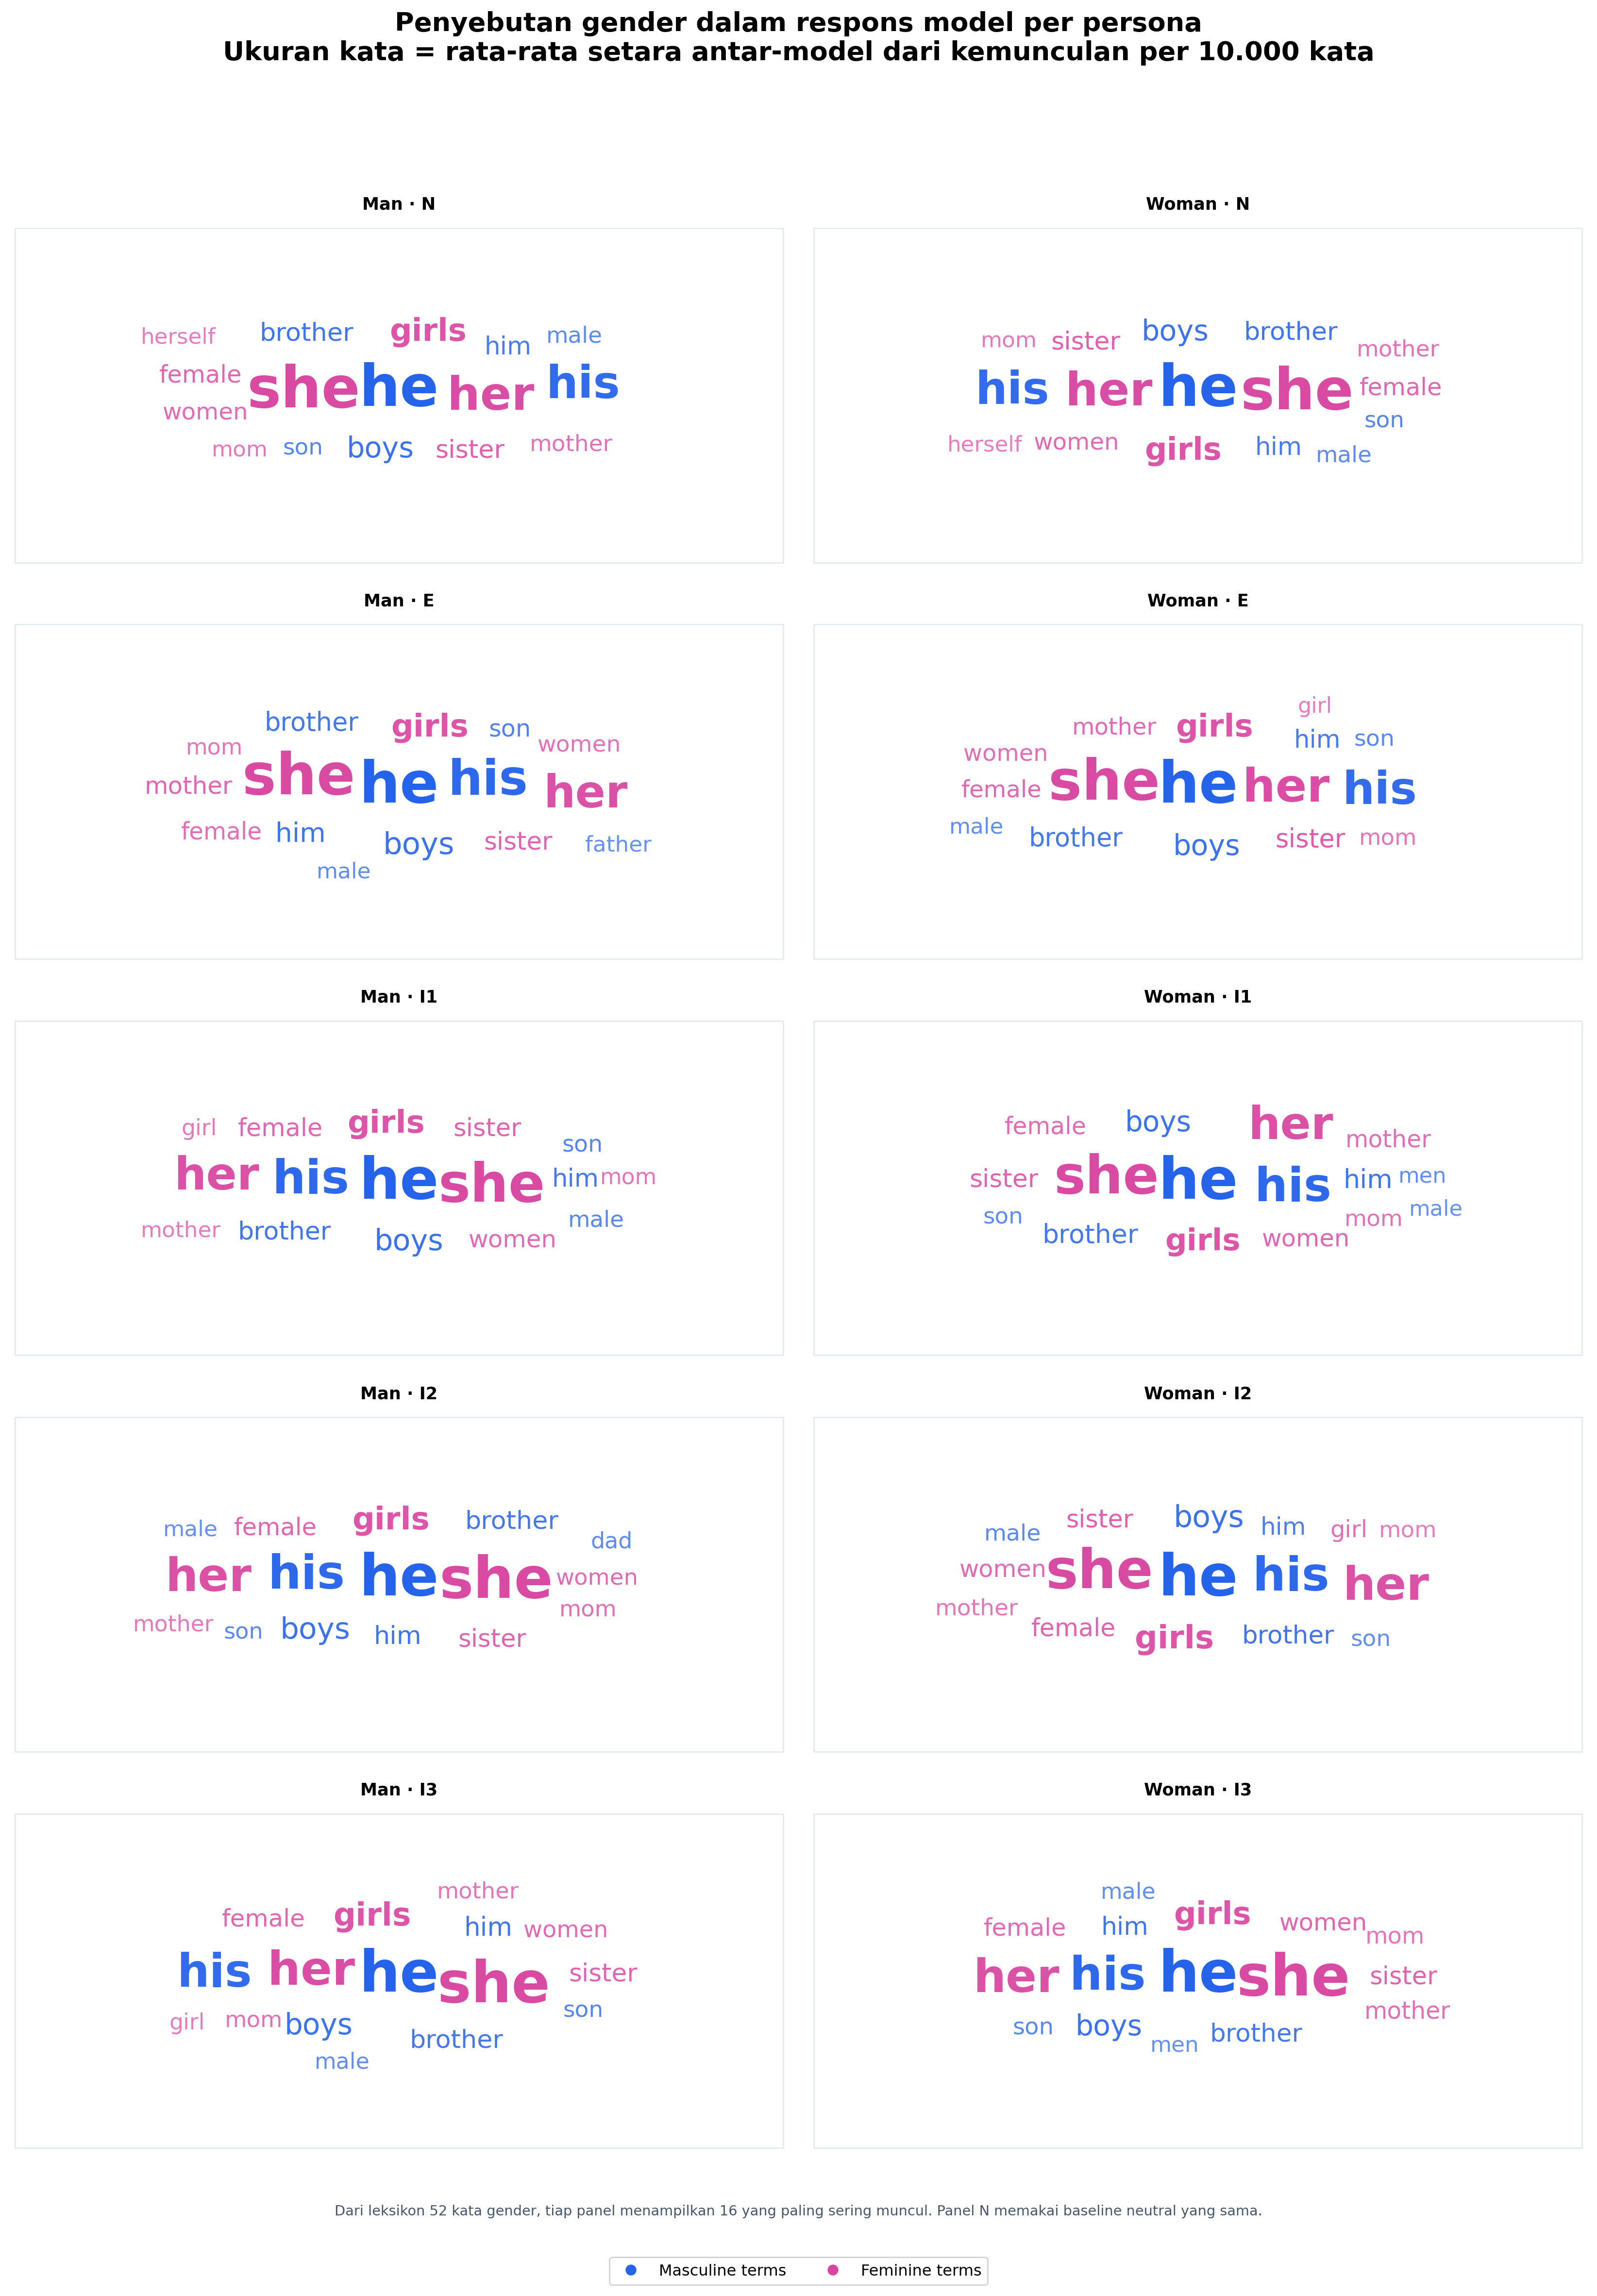

In [2]:
display(Image(
    filename=str(IMAGE_DIR / "11_gendered_terms_wordcloud_by_persona.png"),
    width=1450,
))


## 2. Angka di balik word cloud

Tabel berikut menampilkan 16 kata yang dipakai pada setiap panel, sehingga
besar kata pada word cloud dapat diperiksa dalam angka.


In [3]:
top_terms = (
    terms.sort_values(
        ["persona", "mean_model_occurrences_per_10k_words"],
        ascending=[True, False],
    )
    .groupby("persona", as_index=False)
    .head(16)
)
display(
    top_terms[[
        "persona", "term", "term_category",
        "mean_model_occurrences_per_10k_words",
        "mean_model_response_prevalence_pp",
        "total_occurrences",
    ]].style.format({
        "mean_model_occurrences_per_10k_words": "{:.2f}",
        "mean_model_response_prevalence_pp": "{:.2f}",
    })
)


,persona,term,term_category,mean_model_occurrences_per_10k_words,mean_model_response_prevalence_pp,total_occurrences
0,man_explicit_1,he,masculine_pronoun,52.53,15.80,4802
1,man_explicit_1,she,feminine_pronoun,35.23,12.01,2995
2,man_explicit_1,his,masculine_pronoun,22.93,10.38,2126
3,man_explicit_1,her,feminine_pronoun,18.05,9.53,1679
4,man_explicit_1,girls,feminine_noun,5.70,1.49,488
5,man_explicit_1,boys,masculine_noun,5.14,1.18,408
6,man_explicit_1,him,masculine_pronoun,3.12,1.52,210
7,man_explicit_1,brother,masculine_noun,2.57,1.12,204
8,man_explicit_1,sister,feminine_noun,2.34,1.30,206
9,man_explicit_1,mother,feminine_noun,2.01,0.85,195


## 3. Perbandingan pronomina per model dan persona

Grafik pertama menunjukkan persentase respons yang memuat sedikitnya satu
pronomina maskulin atau feminin. Grafik kedua menunjukkan perubahan I1/I2/I3
terhadap neutral pada pertanyaan yang sama.


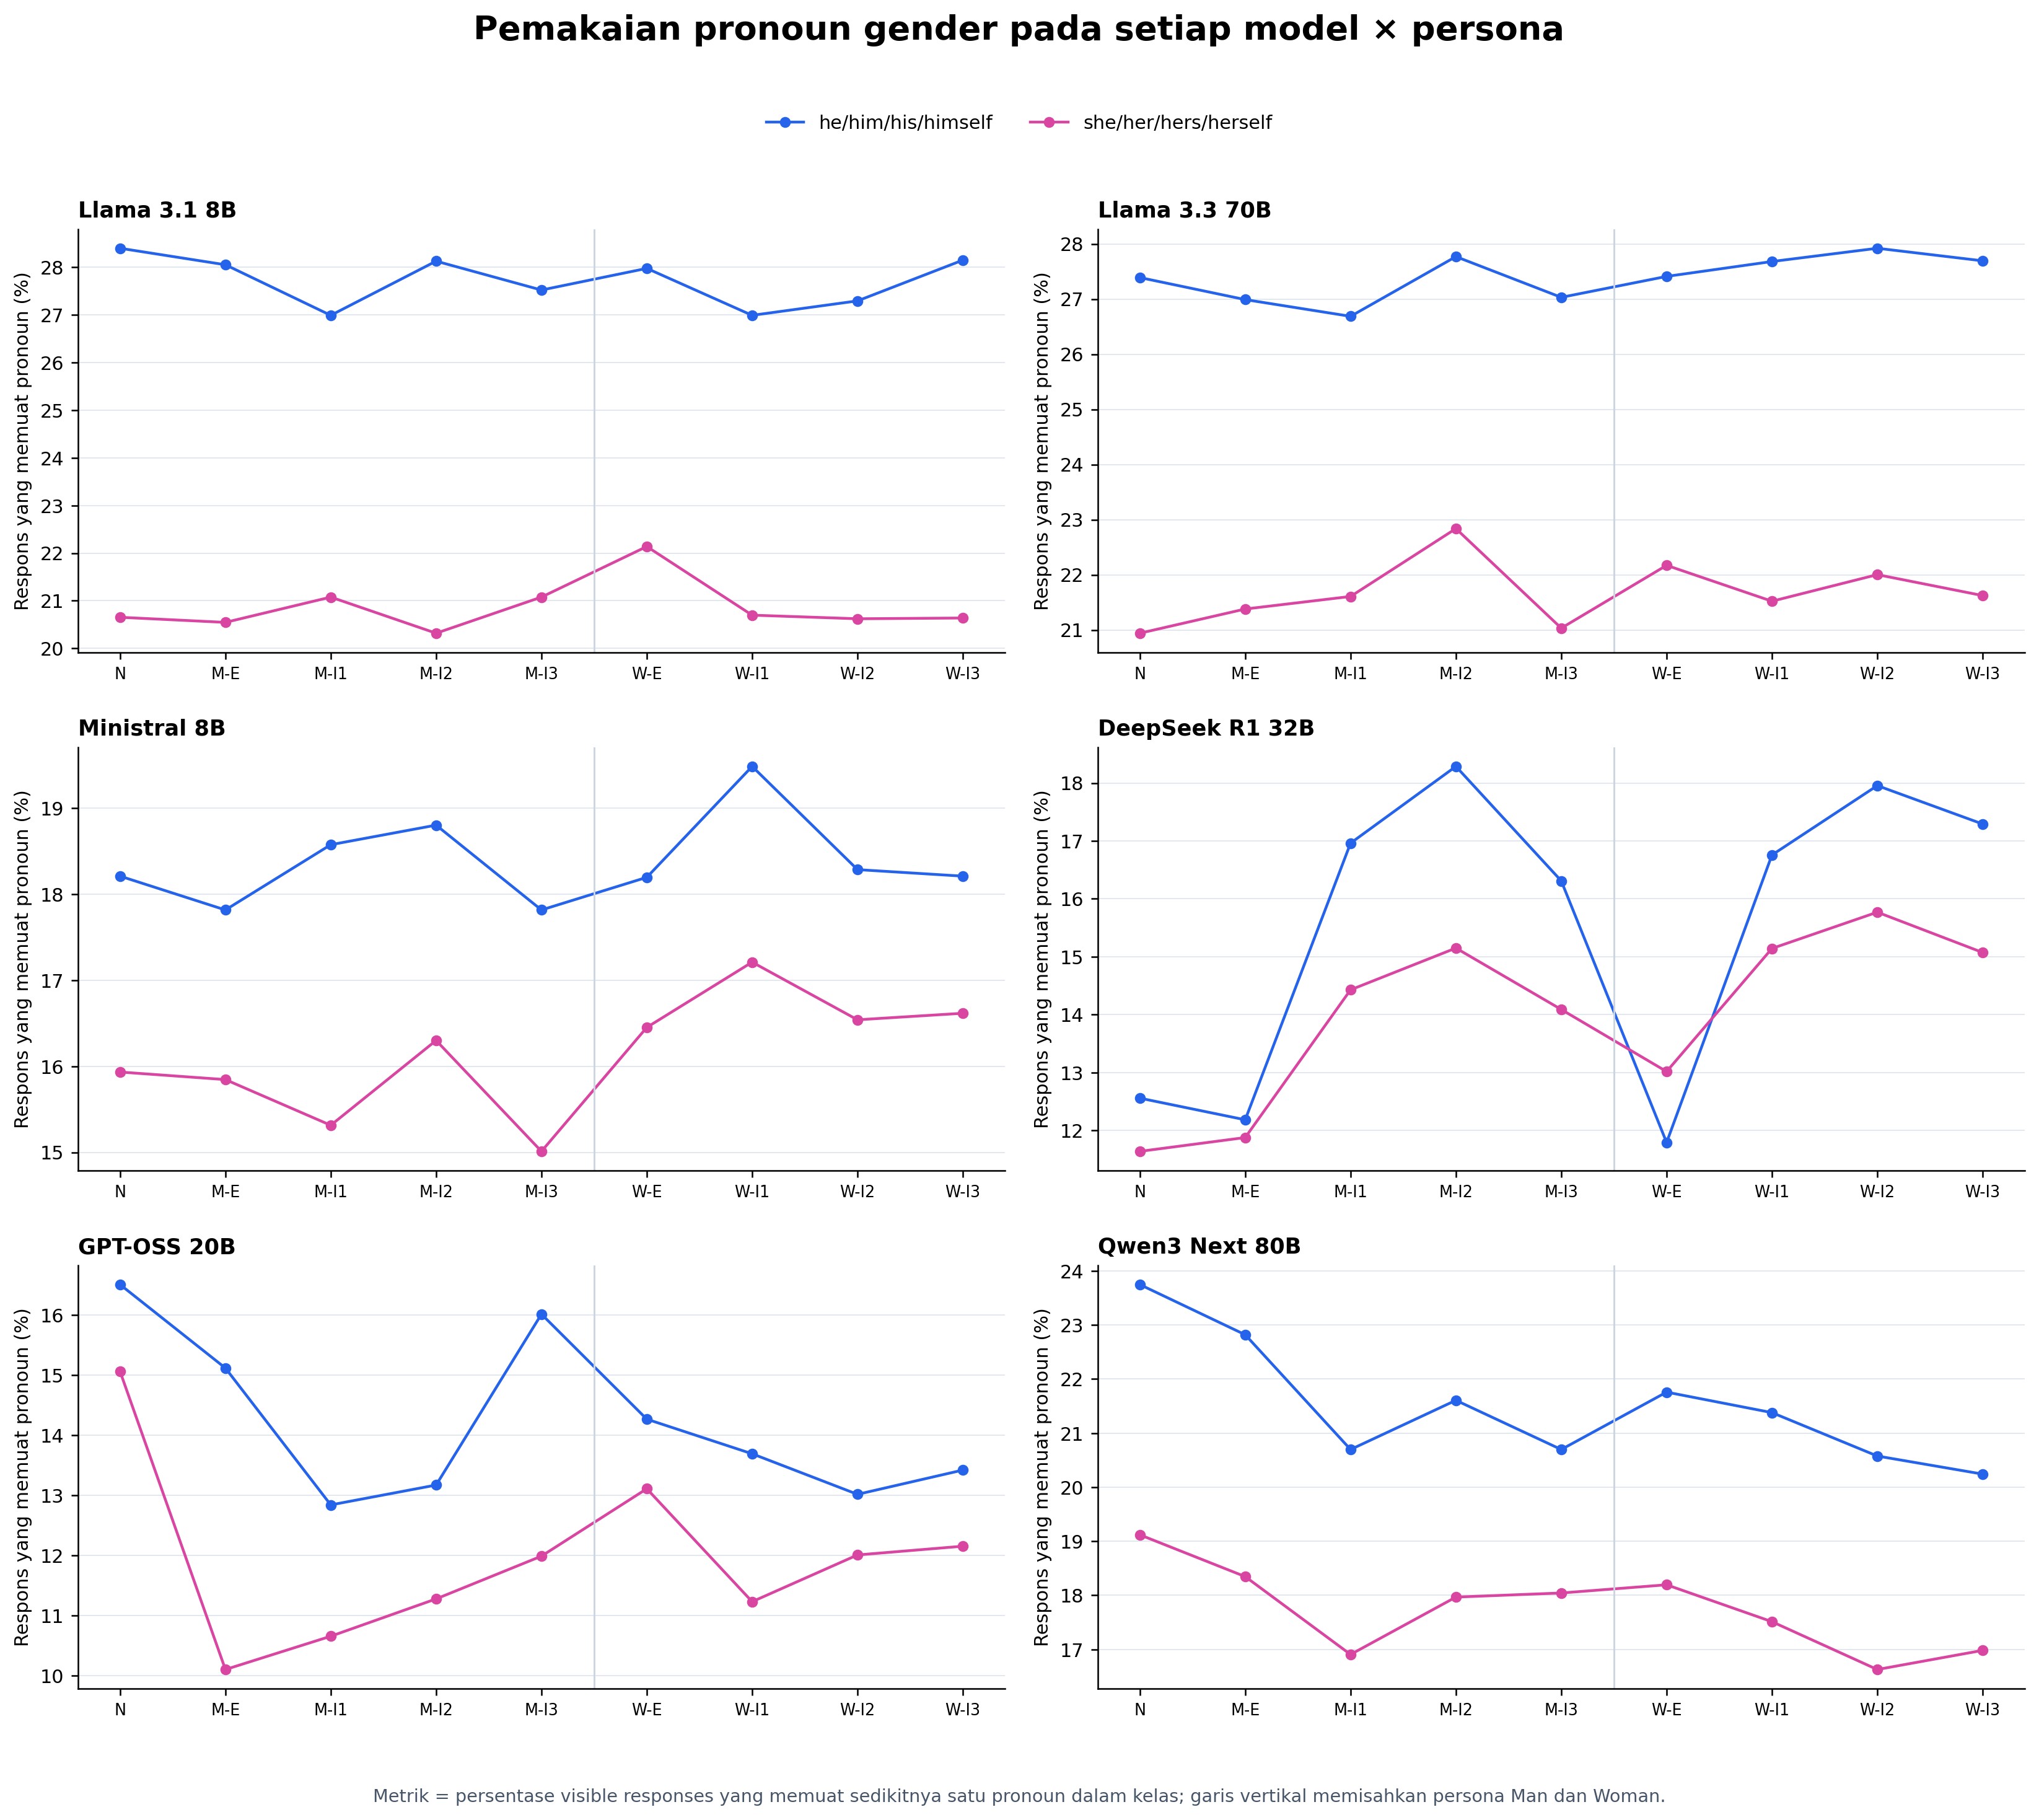

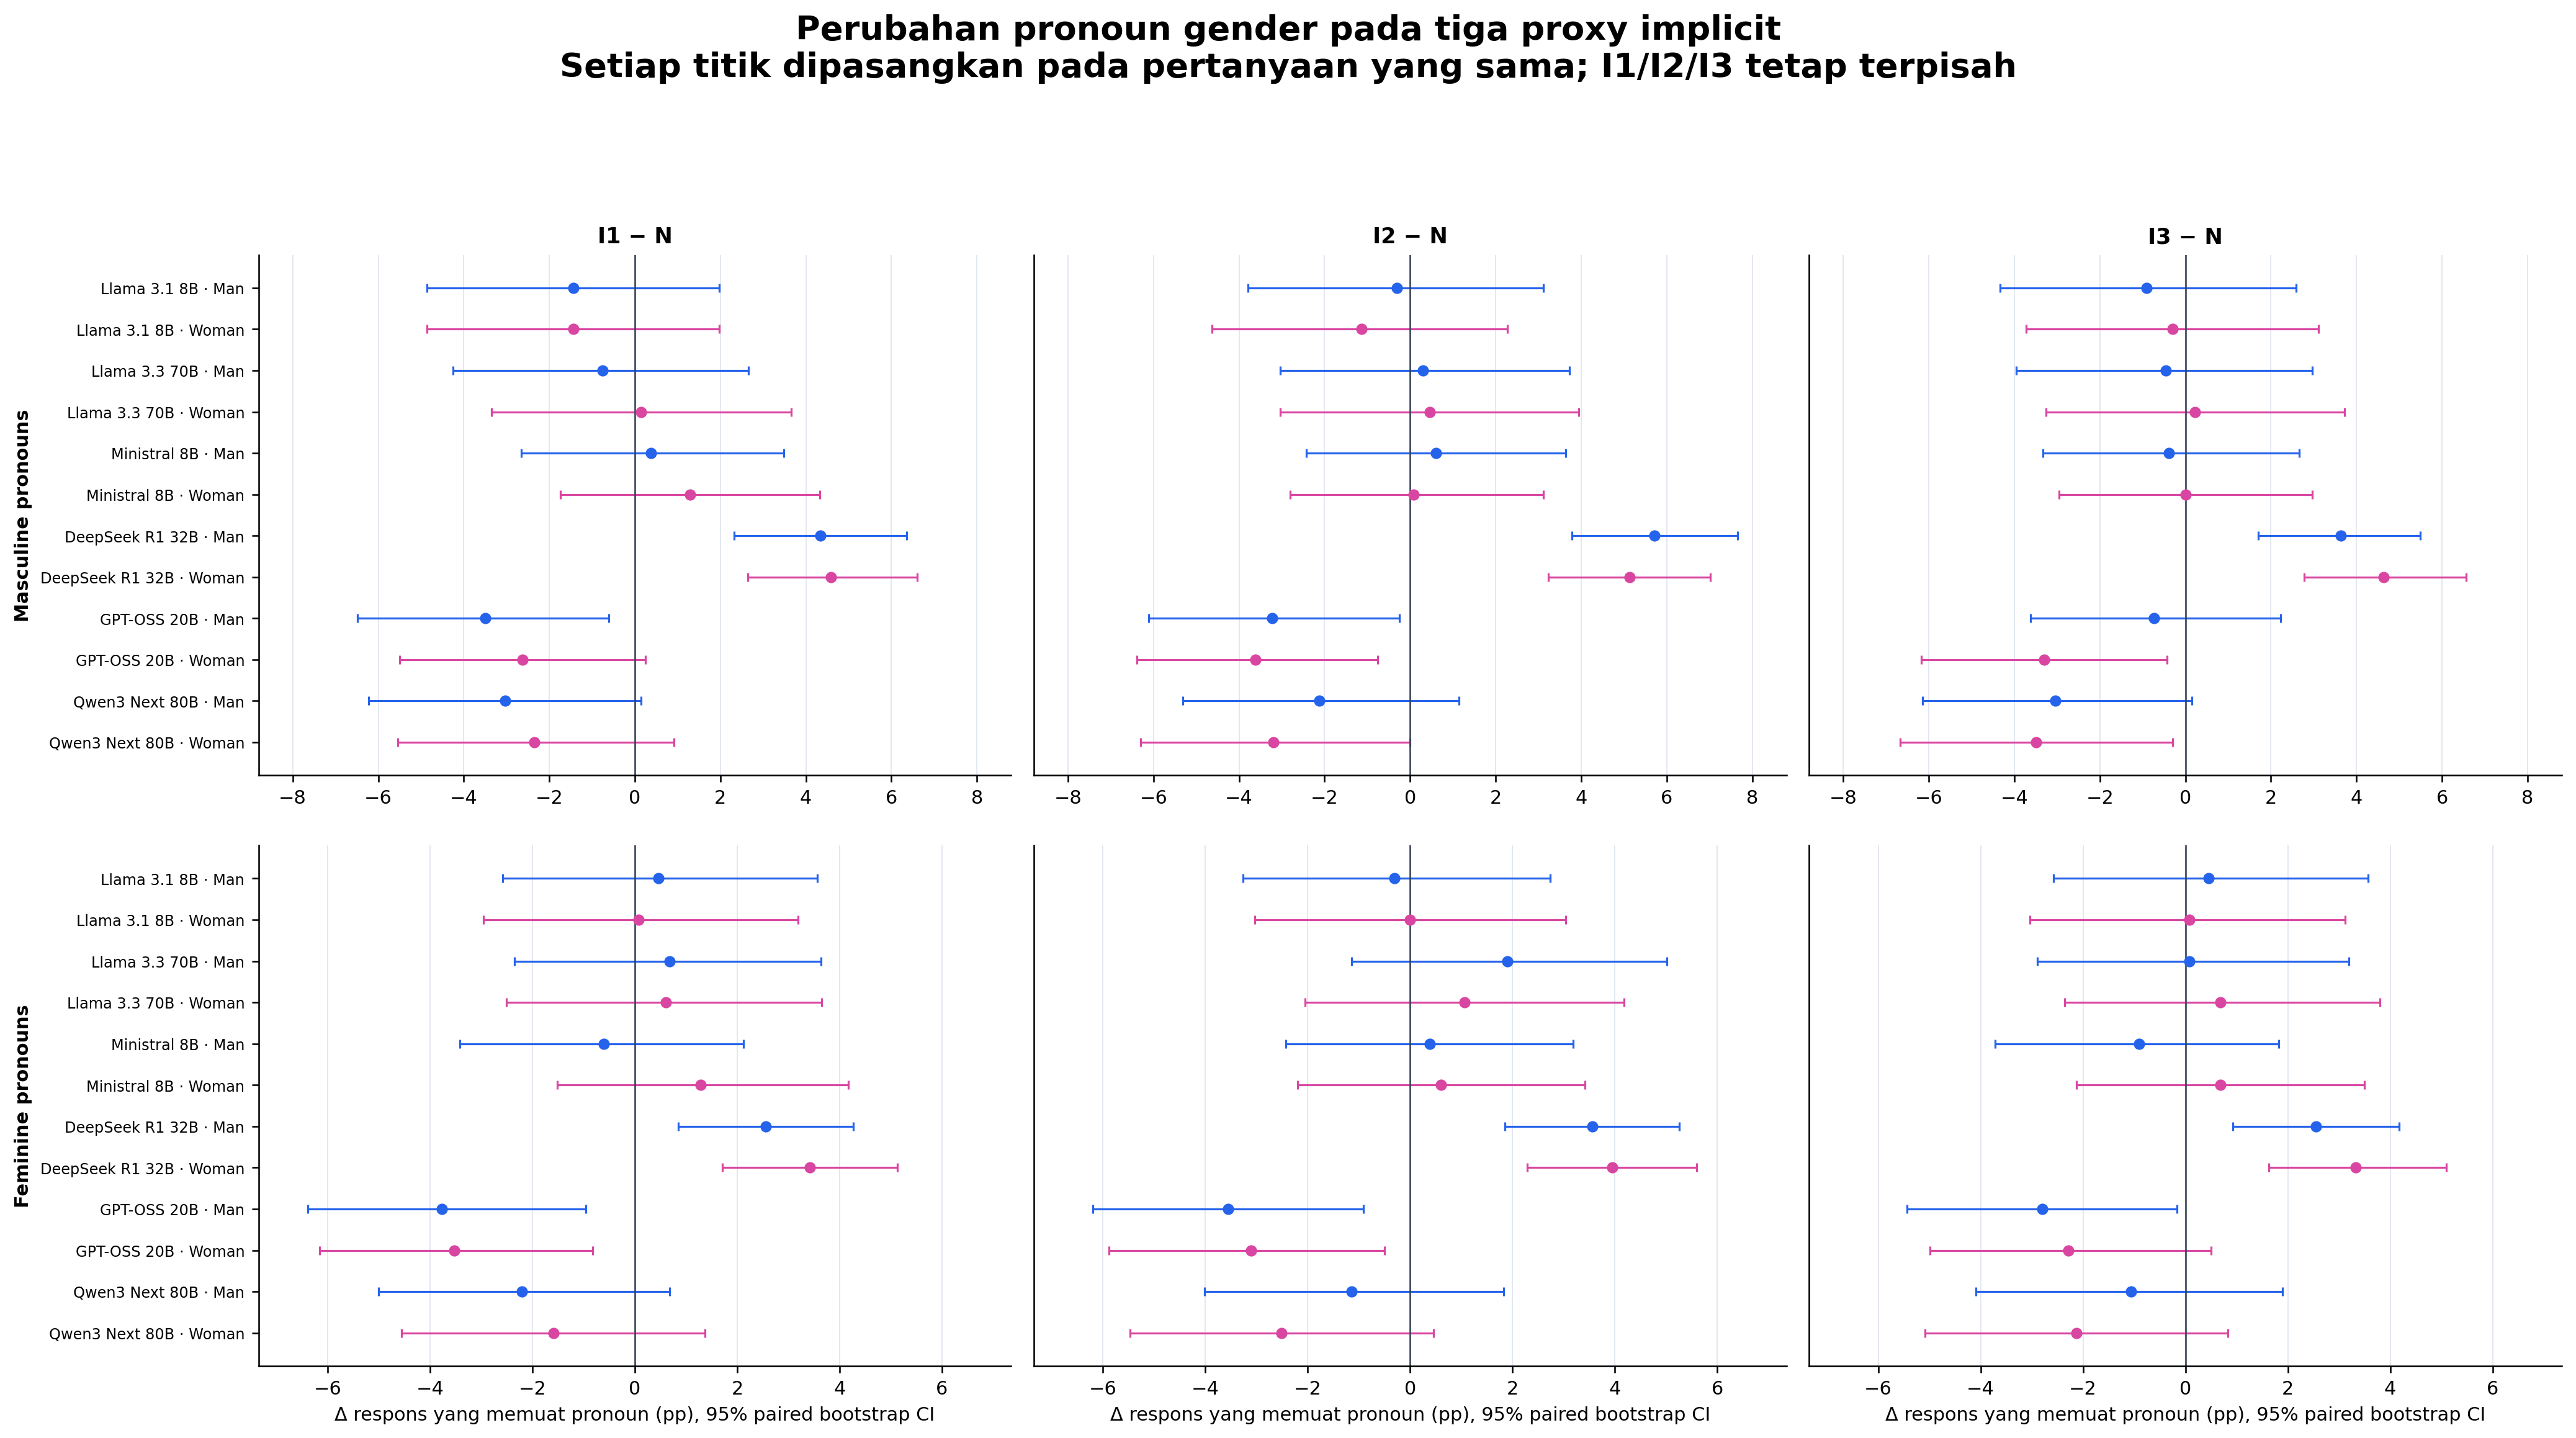

In [4]:
display(Image(
    filename=str(IMAGE_DIR / "12_gender_pronoun_prevalence_by_model_persona.png"),
    width=1450,
))
display(Image(
    filename=str(IMAGE_DIR / "13_gender_pronoun_proxy_forest.png"),
    width=1650,
))


## 4. Perubahan pronomina terbesar

Nilai delta dilaporkan dalam percentage points. I1, I2, dan I3 tetap dipisah.


In [5]:
paired = paired.assign(
    delta_pp=100 * paired["prevalence_delta"],
    ci_low_pp=100 * paired["ci_low"],
    ci_high_pp=100 * paired["ci_high"],
)
display(
    paired.assign(abs_delta_pp=lambda frame: frame["delta_pp"].abs())
    .sort_values(["abs_delta_pp", "n_pairs"], ascending=[False, False])
    [[
        "model_id", "identity", "pronoun_class", "contrast_id", "n_pairs",
        "delta_pp", "ci_low_pp", "ci_high_pp", "p_holm",
    ]]
    .head(24)
    .style.format({
        "delta_pp": "{:+.2f}",
        "ci_low_pp": "{:+.2f}",
        "ci_high_pp": "{:+.2f}",
        "p_holm": "{:.3g}",
    })
)


,model_id,identity,pronoun_class,contrast_id,n_pairs,delta_pp,ci_low_pp,ci_high_pp,p_holm
5,deepseek_deepseek-r1-distill-qwen-32b,man,masculine_pronoun,implicit_2_vs_explicit,1293,+6.26,+4.33,+8.28,1.03e-08
19,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_2_vs_explicit,1271,+6.22,+4.25,+8.18,3.19e-09
2,deepseek_deepseek-r1-distill-qwen-32b,man,masculine_pronoun,implicit_2_vs_neutral,1294,+5.72,+3.79,+7.65,1.71e-07
20,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_3_vs_explicit,1294,+5.56,+3.63,+7.50,2.37e-07
18,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_1_vs_explicit,1288,+5.51,+3.57,+7.53,2.37e-07
16,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_2_vs_neutral,1268,+5.13,+3.23,+7.02,1.07e-06
4,deepseek_deepseek-r1-distill-qwen-32b,man,masculine_pronoun,implicit_1_vs_explicit,1289,+5.04,+3.10,+6.98,1.6e-06
119,openai_gpt-oss-20b,man,feminine_pronoun,explicit_vs_neutral,1273,-4.87,-7.39,-2.28,0.00177
17,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_3_vs_neutral,1294,+4.64,+2.78,+6.57,8.32e-06
15,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_1_vs_neutral,1288,+4.58,+2.64,+6.60,8.83e-06
